# 1. Load Manhattan NTA boundaries

In [1]:
import geopandas as gpd
from pathlib import Path

RAW = Path("../data/raw")
PROCESSED = Path("../data/processed")

nta = gpd.read_file(RAW / "nynta2020.shp")
nta.head()

,BoroCode,BoroName,CountyFIPS,NTA2020,NTAName,NTAAbbrev,NTAType,CDTA2020,CDTAName,Shape_Leng,Shape_Area,geometry
0,3,Brooklyn,047,BK0101,Greenpoint,Grnpt,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),28919.560728,3.532181e+07,"POLYGON ((1003059.997 204572.025, 1002991.367 ..."
1,3,Brooklyn,047,BK0102,Williamsburg,Wllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),28134.082737,2.885285e+07,"POLYGON ((995851.916 203199.332, 995969.193 20..."
2,3,Brooklyn,047,BK0103,South Williamsburg,SWllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),18250.280091,1.520896e+07,"POLYGON ((998047.21 196303.325, 998157.901 196..."
3,3,Brooklyn,047,BK0104,East Williamsburg,EWllmsbrg,0,BK01,BK01 Williamsburg-Greenpoint (CD 1 Equivalent),43184.800376,5.226741e+07,"POLYGON ((1005302.497 199455.73, 1005307.792 1..."
4,3,Brooklyn,047,BK0201,Brooklyn Heights,BkHts,0,BK02,BK02 Downtown Brooklyn-Fort Greene (CD 2 Appro...,14312.192285,9.982023e+06,"POLYGON ((986367.736 190549.239, 985813.836 19..."


In [2]:
nta_manhattan = nta[nta["BoroName"] == "Manhattan"].copy()
print("Manhattan NTAs:", len(nta_manhattan))
nta_manhattan[["NTA2020", "NTAName"]].head(10)

Manhattan NTAs: 38


,NTA2020,NTAName
118,MN0101,Financial District-Battery Park City
119,MN0102,Tribeca-Civic Center
120,MN0191,The Battery-Governors Island-Ellis Island-Libe...
121,MN0201,SoHo-Little Italy-Hudson Square
122,MN0202,Greenwich Village
123,MN0203,West Village
124,MN0301,Chinatown-Two Bridges
125,MN0302,Lower East Side
126,MN0303,East Village
127,MN0401,Chelsea-Hudson Yards


In [3]:
print("CRS:", nta_manhattan.crs)

CRS: EPSG:2263


<Axes: xlabel='Easting [US survey foot]', ylabel='Northing [US survey foot]'>

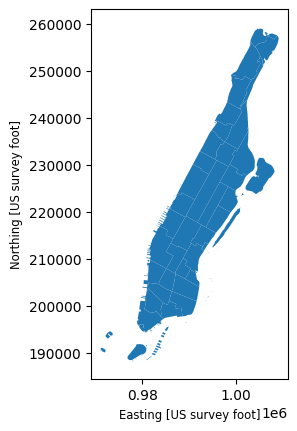

In [4]:
nta_manhattan.plot()

# 2. Load ACS household income data

In [5]:
import os

for f in os.listdir(RAW):
    print(f)

Affordable_Housing_Production_by_Building_20261102.csv
ACSDT5Y2024.B19025-Data.csv
ACSDT5Y2024.B11001-Table-Notes.txt
acs_household.csv
nynta2020.dbf
nynta2020.shx
nynta2020.shp
ACSDT5Y2024.B19025-Table-Notes.txt
nyct2020.prj
nyct2020.shp.xml
nyc_pluto.zip
ACSDT5Y2024.B25070-2026-11-02T121937.csv
nyct2020.dbf
acs_income.csv
nyct2020.shx
nynta2020.prj
nyct2020.shp
ACSDT5Y2024.B11001-Data.csv
nynta2020.shp.xml


In [6]:
import pandas as pd

income = pd.read_csv(RAW / "ACSDT5Y2024.B19025-Data.csv")
households = pd.read_csv(RAW / "ACSDT5Y2024.B11001-Data.csv")

print("Income shape:", income.shape)
print("Households shape:", households.shape)

Income shape: (85385, 5)
Households shape: (85385, 21)


/var/folders/bs/x8kwr7tx2yn1x05tvj7m0nc40000gn/T/ipykernel_84773/2816256146.py:4: DtypeWarning: Columns (2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19) have mixed types. Specify dtype option on import or set low_memory=False.
  households = pd.read_csv(RAW / "ACSDT5Y2024.B11001-Data.csv")


In [7]:
print("Income columns:")
print(income.columns.tolist())

print("\nHousehold columns:")
print(households.columns.tolist())

Income columns:
['GEO_ID', 'NAME', 'B19025_001E', 'B19025_001M', 'Unnamed: 4']

Household columns:
['GEO_ID', 'NAME', 'B11001_001E', 'B11001_001M', 'B11001_002E', 'B11001_002M', 'B11001_003E', 'B11001_003M', 'B11001_004E', 'B11001_004M', 'B11001_005E', 'B11001_005M', 'B11001_006E', 'B11001_006M', 'B11001_007E', 'B11001_007M', 'B11001_008E', 'B11001_008M', 'B11001_009E', 'B11001_009M', 'Unnamed: 20']


In [8]:
households.head()

,GEO_ID,NAME,B11001_001E,B11001_001M,B11001_002E,B11001_002M,B11001_003E,B11001_003M,B11001_004E,B11001_004M,...,B11001_005M,B11001_006E,B11001_006M,B11001_007E,B11001_007M,B11001_008E,B11001_008M,B11001_009E,B11001_009M,Unnamed: 20
0,Geography,Geographic Area Name,Estimate!!Total:,Margin of Error!!Total:,Estimate!!Total:!!Family households:,Margin of Error!!Total:!!Family households:,Estimate!!Total:!!Family households:!!Married-...,Margin of Error!!Total:!!Family households:!!M...,Estimate!!Total:!!Family households:!!Other fa...,Margin of Error!!Total:!!Family households:!!O...,...,Margin of Error!!Total:!!Family households:!!O...,Estimate!!Total:!!Family households:!!Other fa...,Margin of Error!!Total:!!Family households:!!O...,Estimate!!Total:!!Nonfamily households:,Margin of Error!!Total:!!Nonfamily households:,Estimate!!Total:!!Nonfamily households:!!House...,Margin of Error!!Total:!!Nonfamily households:...,Estimate!!Total:!!Nonfamily households:!!House...,Margin of Error!!Total:!!Nonfamily households:...,NaN
1,0400000US36,New York,7722646,12717,4738075,13456,3279487,15988,1458588,9559,...,5898,1060419,8193,2984571,12394,2398170,12430,586401,7149,NaN
2,0500000US36061,"New York County, New York",778281,4924,320699,4352,214047,3855,106652,3051,...,1848,82122,2535,457582,5503,369128,5037,88454,2669,NaN
3,1400000US01001020100,Census Tract 201; Autauga County; Alabama,736,137,521,134,399,139,122,51,...,32,82,45,215,68,174,55,41,47,NaN
4,1400000US01001020200,Census Tract 202; Autauga County; Alabama,592,114,402,100,160,54,242,96,...,58,171,83,190,64,188,65,2,5,NaN


In [9]:
income.head()


,GEO_ID,NAME,B19025_001E,B19025_001M,Unnamed: 4
0,Geography,Geographic Area Name,Estimate!!Aggregate household income in the pa...,Margin of Error!!Aggregate household income in...,NaN
1,0400000US36,New York,990409253700,5271114011,NaN
2,0500000US36061,"New York County, New York",151076814100,2372140897,NaN
3,1400000US01001020100,Census Tract 201; Autauga County; Alabama,59209600,13040834,NaN
4,1400000US01001020200,Census Tract 202; Autauga County; Alabama,49983400,11500157,NaN


In [10]:
income = pd.read_csv(
    RAW / "ACSDT5Y2024.B19025-Data.csv",
    skiprows=[1]
)

households = pd.read_csv(
    RAW / "ACSDT5Y2024.B11001-Data.csv",
    skiprows=[1]
)

In [11]:
income.head()
households.head()

,GEO_ID,NAME,B11001_001E,B11001_001M,B11001_002E,B11001_002M,B11001_003E,B11001_003M,B11001_004E,B11001_004M,...,B11001_005M,B11001_006E,B11001_006M,B11001_007E,B11001_007M,B11001_008E,B11001_008M,B11001_009E,B11001_009M,Unnamed: 20
0,0400000US36,New York,7722646,12717,4738075,13456,3279487,15988,1458588,9559,...,5898,1060419,8193,2984571,12394,2398170,12430,586401,7149,NaN
1,0500000US36061,"New York County, New York",778281,4924,320699,4352,214047,3855,106652,3051,...,1848,82122,2535,457582,5503,369128,5037,88454,2669,NaN
2,1400000US01001020100,Census Tract 201; Autauga County; Alabama,736,137,521,134,399,139,122,51,...,32,82,45,215,68,174,55,41,47,NaN
3,1400000US01001020200,Census Tract 202; Autauga County; Alabama,592,114,402,100,160,54,242,96,...,58,171,83,190,64,188,65,2,5,NaN
4,1400000US01001020300,Census Tract 203; Autauga County; Alabama,1235,169,821,170,545,155,276,134,...,31,251,131,414,99,371,101,43,50,NaN


In [12]:
# Keeping only Manhattan census tracts
income = income[
    income["GEO_ID"].str.startswith("1400000US36061", na=False)
].copy()

households = households[
    households["GEO_ID"].str.startswith("1400000US36061", na=False)
].copy()

print("Income tract rows:", len(income))
print("Household tract rows:", len(households))

Income tract rows: 310
Household tract rows: 310


In [13]:
# We only need these columns
income = income[
    ["GEO_ID", "NAME", "B19025_001E"]
].copy()
households = households[
    ["GEO_ID", "NAME", "B11001_001E"]
].copy()

In [14]:
income = income.rename(columns={
    "B19025_001E": "aggregate_household_income"
})

households = households.rename(columns={
    "B11001_001E": "total_households"
})

In [15]:
income["aggregate_household_income"] = pd.to_numeric(
    income["aggregate_household_income"],
    errors="coerce"
)

households["total_households"] = pd.to_numeric(
    households["total_households"],
    errors="coerce"
)

In [16]:
# Both tables have the same GEO_ID so we combine them
acs = income.merge(
    households[["GEO_ID", "total_households"]],
    on="GEO_ID",
    how="inner"
)

acs.head()

,GEO_ID,NAME,aggregate_household_income,total_households
0,1400000US36061000100,Census Tract 1; New York County; New York,NaN,0
1,1400000US36061000201,Census Tract 2.01; New York County; New York,41625500.0,852
2,1400000US36061000202,Census Tract 2.02; New York County; New York,220922500.0,3163
3,1400000US36061000500,Census Tract 5; New York County; New York,NaN,0
4,1400000US36061000600,Census Tract 6; New York County; New York,344101000.0,5393


In [17]:
print("Final Manhattan ACS tract rows:", len(acs))
print("Missing income:", acs["aggregate_household_income"].isna().sum())
print("Missing households:", acs["total_households"].isna().sum())

acs.head()

Final Manhattan ACS tract rows: 310
Missing income: 9
Missing households: 0


,GEO_ID,NAME,aggregate_household_income,total_households
0,1400000US36061000100,Census Tract 1; New York County; New York,NaN,0
1,1400000US36061000201,Census Tract 2.01; New York County; New York,41625500.0,852
2,1400000US36061000202,Census Tract 2.02; New York County; New York,220922500.0,3163
3,1400000US36061000500,Census Tract 5; New York County; New York,NaN,0
4,1400000US36061000600,Census Tract 6; New York County; New York,344101000.0,5393


In [18]:
acs.loc[
    acs["aggregate_household_income"].isna(),
    ["GEO_ID", "NAME", "aggregate_household_income", "total_households"]
]

,GEO_ID,NAME,aggregate_household_income,total_households
0,1400000US36061000100,Census Tract 1; New York County; New York,NaN,0
3,1400000US36061000500,Census Tract 5; New York County; New York,NaN,0
87,1400000US36061008602,Census Tract 86.02; New York County; New York,NaN,0
158,1400000US36061014300,Census Tract 143; New York County; New York,NaN,0
244,1400000US36061021703,Census Tract 217.03; New York County; New York,NaN,0
271,1400000US36061024000,Census Tract 240; New York County; New York,NaN,0
301,1400000US36061029700,Census Tract 297; New York County; New York,NaN,0
306,1400000US36061031100,Census Tract 311; New York County; New York,NaN,0
309,1400000US36061031900,Census Tract 319; New York County; New York,NaN,0


In [19]:
acs["tract_geoid"] = acs["GEO_ID"].str.replace("1400000US", "", regex=False)
acs[["GEO_ID", "tract_geoid", "NAME"]].head()
# tract_geoid will be what we use to connect the ACS table to actual census tract geometry

,GEO_ID,tract_geoid,NAME
0,1400000US36061000100,36061000100,Census Tract 1; New York County; New York
1,1400000US36061000201,36061000201,Census Tract 2.01; New York County; New York
2,1400000US36061000202,36061000202,Census Tract 2.02; New York County; New York
3,1400000US36061000500,36061000500,Census Tract 5; New York County; New York
4,1400000US36061000600,36061000600,Census Tract 6; New York County; New York


In [20]:
# Remove tracts with no households
acs_clean = acs[
    (acs["total_households"] > 0) &
    (acs["aggregate_household_income"].notna())
].copy()

print("Rows before cleaning:", len(acs))
print("Rows after cleaning:", len(acs_clean))
print("Rows removed:", len(acs) - len(acs_clean))

Rows before cleaning: 310
Rows after cleaning: 301
Rows removed: 9


In [21]:
acs_clean.to_csv(
    PROCESSED / "manhattan_acs_income_by_tract.csv",
    index=False
)

# 3. Load HPD affordable housing data

In [22]:
import sys
sys.path.append("..")
from analysis.data_processing import process_hpd_data

hpd = process_hpd_data(RAW / "Affordable_Housing_Production_by_Building_20261102.csv", borough="Manhattan")
hpd.head()

Manhattan filter: (84.45%) removed from 9551 to 1485
Missing coordinates filter: (5.79%) removed from 1485 to 1399
Deduplication filter: (0.00%) removed from 1399 to 1399


,Project ID,Project Name,Building ID,Project Start Date,Reporting Construction Type,Latitude,Longitude,Extremely Low Income Units,Very Low Income Units,Low Income Units,Moderate Income Units,Middle Income Units,Other Income Units,All Counted Units,Total Units
2,72449,BREMOND KING DAVIS.YR15.FY26,21199.0,06/30/2026,Preservation,40.820728,-73.945285,12.0,13.0,0.0,0.0,0.0,0.0,25.0,25
3,72449,BREMOND KING DAVIS.YR15.FY26,28145.0,06/30/2026,Preservation,40.820717,-73.946322,6.0,9.0,0.0,0.0,0.0,1.0,16.0,16
4,72449,BREMOND KING DAVIS.YR15.FY26,40555.0,06/30/2026,Preservation,40.813338,-73.943026,5.0,10.0,0.0,0.0,0.0,0.0,15.0,15
5,72449,BREMOND KING DAVIS.YR15.FY26,40578.0,06/30/2026,Preservation,40.813698,-73.943889,7.0,11.0,0.0,0.0,0.0,1.0,19.0,19
6,72449,BREMOND KING DAVIS.YR15.FY26,40586.0,06/30/2026,Preservation,40.813750,-73.944008,6.0,4.0,0.0,0.0,0.0,0.0,10.0,10


In [23]:
hpd[["All Counted Units", "Total Units"]].describe()

,All Counted Units,Total Units
count,1399.000000,1399.000000
mean,53.010722,77.597570
std,73.821523,128.388199
min,1.000000,1.000000
25%,10.000000,14.000000
50%,21.000000,24.000000
75%,59.000000,93.000000
max,611.000000,1320.000000


# 4. Spatial join of HPD buildings to Manhattan NTAs

In [24]:
from analysis.data_processing import points_lonlat, spatial_join_to_nta

hpd_points = points_lonlat(hpd)
print("CRS:", hpd_points.crs)

CRS: EPSG:2263


In [25]:
hpd_nta = spatial_join_to_nta(hpd_points, nta_manhattan, ["NTA2020", "NTAName"])
hpd_nta.head()

Spatial join to NTA: (0.36%) removed from 1399 to 1394


,Project ID,Project Name,Building ID,Project Start Date,Reporting Construction Type,Latitude,Longitude,Extremely Low Income Units,Very Low Income Units,Low Income Units,Moderate Income Units,Middle Income Units,Other Income Units,All Counted Units,Total Units,geometry,NTA2020,NTAName
2,72449,BREMOND KING DAVIS.YR15.FY26,21199.0,06/30/2026,Preservation,40.820728,-73.945285,12.0,13.0,0.0,0.0,0.0,0.0,25.0,25,POINT (999393.945 238295.242),MN1002,Harlem (North)
3,72449,BREMOND KING DAVIS.YR15.FY26,28145.0,06/30/2026,Preservation,40.820717,-73.946322,6.0,9.0,0.0,0.0,0.0,1.0,16.0,16,POINT (999106.928 238291.057),MN1002,Harlem (North)
4,72449,BREMOND KING DAVIS.YR15.FY26,40555.0,06/30/2026,Preservation,40.813338,-73.943026,5.0,10.0,0.0,0.0,0.0,0.0,15.0,15,POINT (1000020.94 235603.199),MN1002,Harlem (North)
5,72449,BREMOND KING DAVIS.YR15.FY26,40578.0,06/30/2026,Preservation,40.813698,-73.943889,7.0,11.0,0.0,0.0,0.0,1.0,19.0,19,POINT (999781.969 235734.205),MN1002,Harlem (North)
6,72449,BREMOND KING DAVIS.YR15.FY26,40586.0,06/30/2026,Preservation,40.813750,-73.944008,6.0,4.0,0.0,0.0,0.0,0.0,10.0,10,POINT (999749.017 235753.13),MN1002,Harlem (North)


In [26]:
hpd_agg = hpd_nta.groupby("NTA2020").agg(
    project_count=("Project ID", "nunique"),
    building_count=("Building ID", "nunique"),
    affordable_units=("All Counted Units", "sum"),
    extremely_low_units=("Extremely Low Income Units", "sum"),
    very_low_units=("Very Low Income Units", "sum"),
    low_units=("Low Income Units", "sum"),
    moderate_units=("Moderate Income Units", "sum"),
    middle_units=("Middle Income Units", "sum"),
    total_building_units=("Total Units", "sum")
).reset_index()

hpd_agg.head()

,NTA2020,project_count,building_count,affordable_units,extremely_low_units,very_low_units,low_units,moderate_units,middle_units,total_building_units
0,MN0101,7,7,900.0,0.0,140.0,275.0,387.0,98.0,3600
1,MN0102,2,2,110.0,86.0,1.0,22.0,0.0,0.0,195
2,MN0201,7,7,297.0,128.0,27.0,125.0,6.0,8.0,751
3,MN0202,2,2,239.0,0.0,175.0,52.0,0.0,12.0,414
4,MN0203,3,3,568.0,175.0,0.0,384.0,0.0,7.0,594


In [27]:
hpd_by_nta = nta_manhattan[["NTA2020", "NTAName", "geometry"]].merge(
    hpd_agg, 
    on="NTA2020", 
    how="left"
)

print("NTAs missing HPD projects:", hpd_by_nta["affordable_units"].isna().sum())

NTAs missing HPD projects: 6


In [28]:
unit_columns = [
    "project_count", "building_count", "affordable_units", 
    "extremely_low_units", "very_low_units", "low_units", 
    "moderate_units", "middle_units", "total_building_units"
]
hpd_by_nta[unit_columns] = hpd_by_nta[unit_columns].fillna(0)
print(f"Total Manhattan NTA count: {len(hpd_by_nta)}")

Total Manhattan NTA count: 38


In [29]:
hpd_by_nta.sort_values("affordable_units", ascending=False).head(10)

,NTA2020,NTAName,geometry,project_count,building_count,affordable_units,extremely_low_units,very_low_units,low_units,moderate_units,middle_units,total_building_units
28,MN1002,Harlem (North),"POLYGON ((1002194.048 242652.581, 1002201.83 2...",83.0,293.0,8124.0,1241.0,3330.0,2206.0,874.0,408.0,8670.0
29,MN1101,East Harlem (South),"POLYGON ((1000577.175 228028.553, 1001238.139 ...",35.0,86.0,8025.0,1655.0,3984.0,952.0,804.0,603.0,8774.0
30,MN1102,East Harlem (North),"MULTIPOLYGON (((1004410.678 229781.419, 100436...",64.0,142.0,6706.0,2061.0,976.0,1968.0,1005.0,662.0,9027.0
13,MN0601,Stuyvesant Town-Peter Cooper Village,"MULTIPOLYGON (((994681.406 203127.675, 994780....",1.0,56.0,5000.0,0.0,0.0,495.0,0.0,4505.0,5000.0
7,MN0302,Lower East Side,"MULTIPOLYGON (((989113.383 196325.093, 989123....",27.0,44.0,4865.0,501.0,3536.0,563.0,101.0,135.0,6102.0
9,MN0401,Chelsea-Hudson Yards,"POLYGON ((983754.619 217001.185, 983857.657 21...",24.0,34.0,4714.0,843.0,774.0,1606.0,641.0,847.0,10210.0
27,MN1001,Harlem (South),"POLYGON ((1000369.738 233326.695, 1000233.777 ...",61.0,118.0,3932.0,1326.0,705.0,1349.0,360.0,159.0,4486.0
10,MN0402,Hell's Kitchen,"POLYGON ((985324.423 221001.9, 985817.17 22072...",33.0,48.0,3230.0,417.0,897.0,1251.0,289.0,365.0,9130.0
32,MN1201,Washington Heights (South),"POLYGON ((1003231.182 248025.828, 1003105.047 ...",29.0,55.0,3036.0,615.0,761.0,1132.0,419.0,87.0,3241.0
6,MN0301,Chinatown-Two Bridges,"POLYGON ((988548.218 197770.375, 988020.966 19...",7.0,19.0,2740.0,481.0,131.0,1545.0,487.0,93.0,2868.0


In [30]:
hpd_by_nta.drop(columns="geometry").to_csv(PROCESSED / "manhattan_hpd_units_by_nta.csv", index=False)

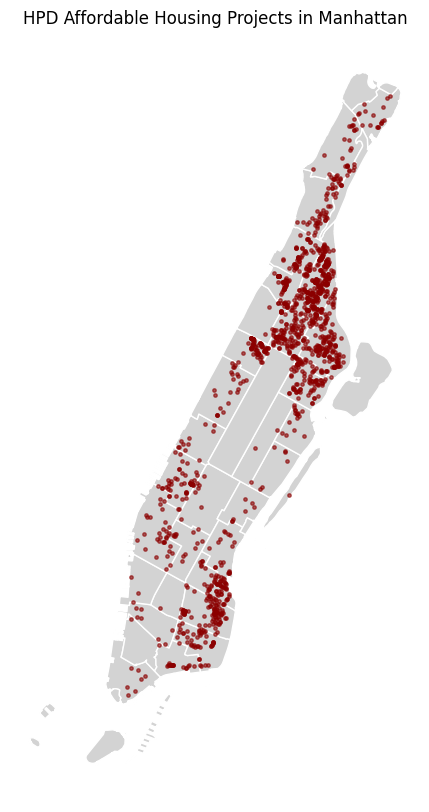

In [31]:
ax = nta_manhattan.plot(color="lightgrey", edgecolor="white", figsize=(6, 10))
hpd_nta.plot(ax=ax, markersize=6, color="darkred", alpha=0.6)
ax.set_title("HPD Affordable Housing Projects in Manhattan", fontsize=12)
ax.set_axis_off()

# 5. Link ACS Census Tract Income Data to NTAs

In [32]:
from analysis.data_processing import record_drops, load_acs_table, aggregate_tracts_to_nta, spatial_join_to_nta

In [33]:
tracts_gdf = gpd.read_file(RAW / "nyct2020.shp")

manhattan_tracts = tracts_gdf[tracts_gdf["BoroName"] == "Manhattan"].copy()
manhattan_tracts["GEOID"] = manhattan_tracts["GEOID"].astype(str)

record_drops("Manhattan Census Tract filter", len(tracts_gdf), len(manhattan_tracts))
manhattan_tracts[["GEOID", "NTA2020", "NTAName"]].head()

Manhattan Census Tract filter: (86.67%) removed from 2325 to 310


,GEOID,NTA2020,NTAName
0,36061000100,MN0191,The Battery-Governors Island-Ellis Island-Libe...
1,36061002201,MN0302,Lower East Side
2,36061002602,MN0303,East Village
3,36061002800,MN0303,East Village
4,36061003400,MN0303,East Village


In [34]:
inc_df = load_acs_table(
    RAW / "ACSDT5Y2024.B19025-Data.csv",
    "GEO_ID",
    columns=["B19025_001E"],
    rename_dict={"B19025_001E": "aggregate_household_income"})

hh_df = load_acs_table(
    RAW / "ACSDT5Y2024.B11001-Data.csv",
    "GEO_ID",
    columns=["B11001_001E"],
    rename_dict={"B11001_001E": "total_households"})

acs_tract = inc_df.merge(hh_df, on="tract_geoid", how="inner", validate="one_to_one")
print(f"Loaded {len(acs_tract)} Manhattan ACS census tracts.")
acs_tract.head()

Manhattan tract filter: (99.64%) removed from 85384 to 310
Manhattan tract filter: (99.64%) removed from 85384 to 310
Loaded 310 Manhattan ACS census tracts.


,tract_geoid,aggregate_household_income,total_households
0,36061000100,NaN,0
1,36061000201,41625500.0,852
2,36061000202,220922500.0,3163
3,36061000500,NaN,0
4,36061000600,344101000.0,5393


In [35]:
acs_tract_clean = acs_tract[
    (acs_tract["total_households"] > 0) &
    (acs_tract["aggregate_household_income"].notna())
].copy()
record_drops("Tracts with no households/income", len(acs_tract), len(acs_tract_clean))

Tracts with no households/income: (2.90%) removed from 310 to 301


In [36]:
tract_points = manhattan_tracts[["GEOID", "NTA2020", "geometry"]].rename(columns={"NTA2020": "NTA2020_dcp"})
tract_points["geometry"] = manhattan_tracts.representative_point()

tract_check = spatial_join_to_nta(tract_points, nta_manhattan, ["NTA2020"])
print("Tracts where DCP and spatial join agree:",
      (tract_check["NTA2020"] == tract_check["NTA2020_dcp"]).sum(), "of", len(tract_check))

Spatial join to NTA: (0.32%) removed from 310 to 309
Tracts where DCP and spatial join agree: 309 of 309


In [37]:
acs_nta = aggregate_tracts_to_nta(acs_tract_clean, manhattan_tracts)
print("NTAs with ACS data:", len(acs_nta))
acs_nta.head()

Tract to NTA crosswalk: (0.00%) removed from 301 to 301
NTAs with ACS data: 33


,NTA2020,aggregate_household_income,total_households,mean_household_income
0,BX0802,1.987438e+08,3355,59238.092399
1,MN0101,6.975094e+09,23144,301378.046146
2,MN0102,4.912388e+09,9638,509689.541399
3,MN0201,3.065082e+09,11840,258875.185811
4,MN0202,4.427376e+09,15537,284956.954367


In [38]:
nta_income = nta_manhattan[["NTA2020", "NTAName", "NTAType", "geometry"]].merge(
    acs_nta,
    on="NTA2020",
    how="left",
    validate="one_to_one"
)

print("Manhattan NTAs:", len(nta_income))
print("NTAs without ACS income:", nta_income["mean_household_income"].isna().sum())
nta_income.loc[nta_income["mean_household_income"].isna(), ["NTA2020", "NTAName", "NTAType"]]

Manhattan NTAs: 38
NTAs without ACS income: 6


,NTA2020,NTAName,NTAType
2,MN0191,The Battery-Governors Island-Ellis Island-Libe...,9
17,MN0661,United Nations,6
31,MN1191,Randall's Island,9
35,MN1291,Highbridge Park,9
36,MN1292,Inwood Hill Park,9
37,MN6491,Central Park,9


In [39]:
nta_income.drop(columns="geometry").to_csv(
    PROCESSED / "manhattan_acs_income_by_nta.csv",
    index=False
)

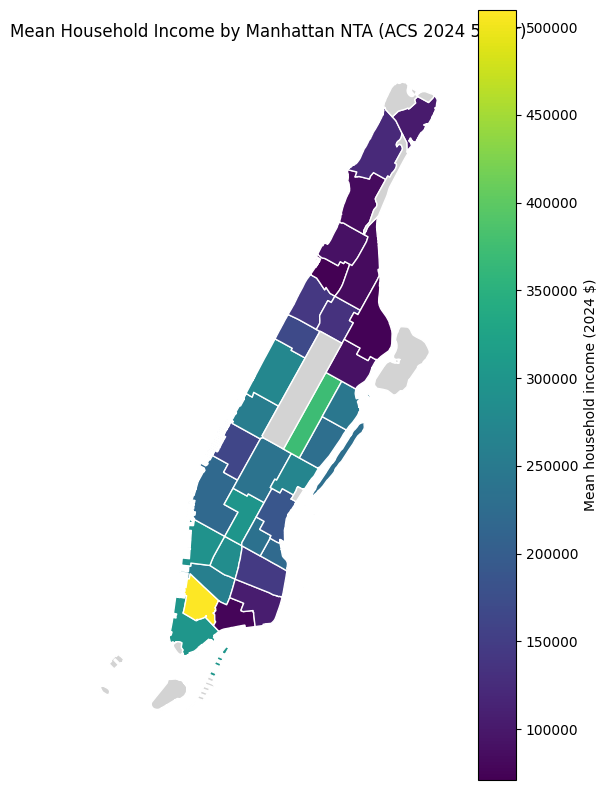

In [40]:
ax = nta_income.plot(
    column="mean_household_income",
    cmap="viridis",
    legend=True,
    legend_kwds={"label": "Mean household income (2024 $)"},
    missing_kwds={"color": "lightgrey", "label": "No households"},
    edgecolor="white",
    figsize=(6, 10)
)
ax.set_title("Mean Household Income by Manhattan NTA (ACS 2024 5-Year)")
ax.set_axis_off()